**Human Movement Intelligence | Biomechanical Load Estimation | Presented by: Reza Saadatyar (2026)**

**07 | Multi-Seed Robustness, GRU/BiGRU, Peak-Loss Ablation and Participant-Level Evidence**

![Stage 07 original lower-body wearable IMU locations and training-only robustness protocol](../../images/07_consolidated_workflow.svg)

**Research question:** Are the apparent improvements in finite-element peak-strain prediction robust to model initialisation and variation among participants, and can recurrent GRU/BiGRU architectures compete with the existing Temporal CNN, Dilated TCN and classical Random Forest benchmark?

**Original data:** Source-verified Essex Figshare v13, 1,729 eligible trials, 101×42 IMU measurements, and 11×2 native-position first and third principal FE strains per trial. **Only the 29 Training participants (1,354 trials) enter new fits and diagnostics in this notebook.** The four previously inspected Validation participants remain outside new tuning or ranking. All four Test participants (183 trials) remain reserved for a separately approved final assessment.

**Predeclared comparison:** Temporal CNN, Dilated TCN, two-layer GRU and two-layer Bidirectional GRU (BiGRU), plus a single controlled Dilated TCN ablation with zero peak-loss weight. All models use the same 35-epoch budget, Training-fold-only normalisation, AdamW, and fixed GroupKFold assignments. Three initialisation/shuffle seeds (2026, 2027, 2028) are assessed: **5 configurations × 3 seeds × 5 folds = 75 Training fits**. Unequal parameter counts are reported rather than falsely presented as capacity-matched.

**Sensitivity evidence:** On one prespecified Dilated TCN seed (2026), we examine the effect of substituting each of the seven original sensor groups by its fold-Training mean, plus one prespecified Gaussian perturbation (0.10 fold-standardised units). These are **Out-of-Fold** sensitivity diagnostics, not causal sensor-importance estimates or claims about physical sensor failures.

**Scientific boundaries:** The previously recorded Stage 05 Random Forest CV score (0.0007950) is a fixed reference, not newly fitted here. Differences are calculated at the participant level; uncertainty intervals are exploratory participant-cluster bootstrap intervals. The earlier four-person Validation cohort has already been inspected repeatedly, so Stage 07 does **not** use it to choose a model. Published FE targets remain model-derived and unitless. Stage 08 is reserved for freezing an approved final protocol and, only after explicit approval, one-time Test evaluation.

**Execution status:** New, unexecuted research implementation. **No Stage 07 model outcomes, stability claims, significance claims or successful quality gate are asserted before genuine execution.**


**00. Colab Repository Setup**

Use the shared non-destructive Git synchroniser before importing Python research modules. The script is the same approved generic setup used by earlier Essex notebooks.


In [1]:
# ======================== 00. Colab Repository Setup =========================

from pathlib import Path
import subprocess
import sys

repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_branch = "main"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")

if not repo_path.exists():
    subprocess.run(["git", "clone", "--branch", repo_branch,
                    repo_url, str(repo_path)], check=True)
elif (
    not (repo_path / "python_modules/core/repository_sync.py").is_file()
    or "def sync_repository(" not in (
        repo_path / "python_modules/core/repository_sync.py"
    ).read_text(encoding="utf-8")
):
    cmd = ["git", "-C", str(repo_path)]
    origin = subprocess.check_output(cmd + ["remote", "get-url", "origin"],
                                     text=True).strip()
    if origin.rstrip("/").removesuffix(".git") != repo_url.removesuffix(".git"):
        raise RuntimeError("Existing repository has an unexpected origin.")
    branch = subprocess.check_output(cmd + ["branch", "--show-current"],
                                     text=True).strip()
    dirty = subprocess.check_output(cmd + ["status", "--porcelain"],
                                    text=True).strip()
    if branch != repo_branch or dirty:
        raise RuntimeError("Cannot migrate a modified or different branch.")
    subprocess.run(cmd + ["pull", "--ff-only", "origin", repo_branch], check=True)
    if "python_modules.core.repository_sync" in sys.modules:
        raise RuntimeError(
            "Repository updated, but the old sync module is already loaded. "
            "Restart the kernel and rerun from the first cell."
        )

sys.path.insert(0, str(repo_path))
from python_modules.core.repository_sync import sync_repository

repo_path = sync_repository(repo_url, repo_branch, parent=repo_path.parent)
%cd {repo_path}


Repository up to date.
/content/human-movement-intelligence


**01. Imports, Shared Device Detection and Research Environment**

Use the established `core.computer_device.computer_device()` helper shared with the completed HARTH project. It reports the detected operating system, CPU, RAM and available NVIDIA/PyTorch GPU information, then returns the supported PyTorch device. The 75 predeclared Training-fold jobs use this single shared device configuration. Job caches remain in Git-ignored `data/processed/`.


In [2]:
# ==================== 01. Environment and Experiment Imports =================
from python_modules.core.colab_setup import setup_colab
root = setup_colab("biomechanical_load_estimation")

import hashlib
import json
from pathlib import Path
from importlib.metadata import version

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure
from core.output_download import download_outputs_from_colab
from essex_figshare import (
    ARTICLE_ID, ARTICLE_VERSION, ensure_pinned_matlab_archive,
    inspect_matlab_archive, extract_matlab_files,
)
from essex_numeric_recovery import check_record_registry
from essex_paired_dataset import (
    build_paired_arrays, paired_source_digest, save_ignored_cache,
)
from essex_timebase_audit import EXPECTED_CHANNELS
from essex_temporal_regression import check_temporal_arrays
from essex_regression_baselines import (
    regression_metrics, participant_metrics, subject_balanced_mae,
)
from essex_stage07_robustness import (
    ARCHITECTURES, NO_PEAK, CONFIGS, SENSOR_SUFFIXES,
    SEEDS, FOLDS, EPOCHS, BATCH_SIZE, PEAK_WEIGHT, LEARNING_RATE,
    sensor_channel_groups, run_cached_fold, paired_subject_bootstrap,
)

plot_style(
    font_family="DejaVu Sans", title_size=12.5, title_weight="normal",
    label_size=11.5, label_weight="normal", tick_size=11,
    legend_size=10, figure_dpi=100, figure_size=(9, 4),
)

study_dir = root / "biomechanical_load_estimation"
raw_dir = root / "data" / "raw" / "essex_femoral_neck_loading"
mat_dir = raw_dir / "matlab_records"
processed_dir = root / "data" / "processed" / "essex_femoral_neck_loading"
output_dir = study_dir / "output"
job_cache_dir = processed_dir / "stage07_training_jobs"
output_dir.mkdir(parents=True, exist_ok=True)
job_cache_dir.mkdir(parents=True, exist_ok=True)
# -------------------- Shared Hardware Inspection and Device ------------------
from core.computer_device import computer_device
device = computer_device()
DEVICE = device.type

print("Predeclared training jobs:", len(CONFIGS) * len(SEEDS) * len(FOLDS))
print("Job caches: local Git-ignored files, not GitHub artifacts.")


Compute device and system information
OS: Linux 6.6.159+
CPU: x86_64
Installed RAM: 12.7 GiB
NVIDIA GPU: Tesla T4
Total VRAM: 15.00 GiB
PyTorch version: 2.11.0+cu130
CUDA device: Tesla T4
CUDA runtime: 13.0
cuDNN version: 92700
PyTorch total VRAM: 14.56 GiB
Selected compute device: cuda
Predeclared training jobs: 75
Job caches: local Git-ignored files, not GitHub artifacts.


**02. Frozen Source, Quality Gates and Split Governance**

Verify the complete source hash lineage, all prior Quality Gates and the participant-disjoint split. Access Stage 05/06 Training-only evidence as context. Neither Validation targets nor reserved Test targets are extracted into the Stage 07 modelling workspace.


In [3]:
# ================== 02. Pinned Stage 04 Evidence and Splits ===================
# -------------------------- 1. Load Saved Evidence --------------------------
paths04 = {
    "gate": output_dir / "04_dataset_and_split_quality_gate.json",
    "manifest": output_dir / "04_local_dataset_build_manifest.json",
    "trials": output_dir / "04_trial_split_assignments.csv",
    "subjects": output_dir / "04_subject_split_assignments.csv",
    "source": output_dir / "01_consolidated_source_and_trial_quality_gate.json",
    "registry": output_dir / "01_original_record_registry.csv",
    "mapping": output_dir / "03_original_time_coordinate_mapping.csv",
}
missing04 = [key for key, path in paths04.items() if not path.is_file()]
if missing04:
    raise FileNotFoundError("Missing committed upstream evidence: " +
                            ", ".join(missing04))
gate04 = json.loads(paths04["gate"].read_text(encoding="utf-8"))
manifest04 = json.loads(paths04["manifest"].read_text(encoding="utf-8"))
source01 = json.loads(paths04["source"].read_text(encoding="utf-8"))
assigned = pd.read_csv(paths04["trials"], dtype=str)
subjects04 = pd.read_csv(paths04["subjects"], dtype=str)
assert gate04["stage04_quality_gate"] == "PASSED"
assert gate04["source_article_id"] == ARTICLE_ID == 30225739
assert gate04["source_version"] == ARTICLE_VERSION == 13
assert gate04["original_sha256"] == source01["archive_sha256"]
assert gate04["original_sha256"] == manifest04["original_archive_sha256"]
assert gate04["canonical_pair_sha256"] == manifest04["canonical_pair_sha256"]
assert manifest04["feature_shape"] == [1729, 101, 42]
assert manifest04["target_shape"] == [1729, 11, 2]
assert gate04["original_source_empty_fe"] == 168
assert gate04["original_target_units_as_published"] == "unitless"

# ------------------------ 2. Freeze Participant Roles -----------------------
expected_splits = {"TRAIN": 1354, "VALIDATION": 192, "TEST": 183}
assert assigned["split"].value_counts().to_dict() == expected_splits
assert assigned["local_record_key"].is_unique
assert len(assigned) == 1729
assert subjects04["subject_id"].is_unique
assert subjects04["split"].value_counts().to_dict() == {
    "TRAIN": 29, "VALIDATION": 4, "TEST": 4,
    "EXCLUDED_NO_FE_TARGET": 3,
}
assert assigned.groupby("subject_id")["split"].nunique().eq(1).all()
assert assigned["split"].eq(
    assigned["subject_id"].map(subjects04.set_index("subject_id")["split"])
).all()
train_mask = assigned["split"].eq("TRAIN").to_numpy()
valid_mask = assigned["split"].eq("VALIDATION").to_numpy()
test_mask = assigned["split"].eq("TEST").to_numpy()
assert not np.any(train_mask & valid_mask)
assert not np.any(train_mask & test_mask)
assert not np.any(valid_mask & test_mask)
print("Frozen Training trials:", train_mask.sum())
print("Frozen Validation trials:", valid_mask.sum())
print("Reserved Test trials (no model access):", test_mask.sum())


# ----------------------- 3. Pin Historical CV Evidence ----------------------
path05 = output_dir / "05_regression_protocol_and_quality_gate.json"
path06 = output_dir / "06_temporal_protocol_and_quality_gate.json"
base_cv_path = output_dir / "05_training_cv_model_summary.csv"
temporal_cv_path = output_dir / "06_training_cv_model_summary.csv"
fold_path = output_dir / "05_training_fold_registry.csv"
prior_subject_path = (
    output_dir / "05_training_cv_subject_activity_metrics.csv"
)
for required in (
    path05, path06, base_cv_path, temporal_cv_path, fold_path,
    prior_subject_path,
):
    if not required.is_file():
        raise FileNotFoundError(f"Missing locked prior evidence: {required}")
gate05 = json.loads(path05.read_text(encoding="utf-8"))
gate06 = json.loads(path06.read_text(encoding="utf-8"))
assert gate05["quality_gate"] == gate06["quality_gate"] == "PASSED"
# Compare the same source fingerprint across all three stages.
# A parenthesised boolean equality must not be compared with a SHA string.
assert (
    gate05["stage04_canonical_pair_sha256"]
    == gate06["canonical_pair_sha256"]
    == gate04["canonical_pair_sha256"]
)
assert gate06["selection_dataset"] == "TRAIN_OOF_ONLY"
assert gate06["selected_temporal_architecture"] == "Dilated TCN"
assert gate05["selected_by_training_cv"] == "Random Forest"
prior_cv = pd.read_csv(base_cv_path)
prior_temporal_cv = pd.read_csv(temporal_cv_path)
prior_rf_cv_mae = float(prior_cv.loc[
    prior_cv["model"].eq("Random Forest"), "subject_balanced_mae"
].iloc[0])
assert abs(prior_rf_cv_mae - 0.0007950357516464314) < 1e-12
print("Stage 04/05/06 source and research gates: VERIFIED")
print("Locked reference: Stage 05 Random Forest Training CV MAE",
      f"{prior_rf_cv_mae:.8f}")
print("Previous Validation outcomes are not used for Stage 07 ranking.")


Frozen Training trials: 1354
Frozen Validation trials: 192
Reserved Test trials (no model access): 183
Stage 04/05/06 source and research gates: VERIFIED
Locked reference: Stage 05 Random Forest Training CV MAE 0.00079504
Previous Validation outcomes are not used for Stage 07 ranking.


**03. Source-Verified Training Cache**

Reuse or reconstruct the pinned Essex MATLAB archive and canonical paired cache. Verify the entire source fingerprint for identity, but copy **Training arrays only** into the new experiment; the Validation and Test partitions are deliberately not materialised as model inputs.


In [4]:
# ============== 03. Verified Cache and Source Reconstruction ================
# ------------------- 1. Pinned Original MATLAB Reader -----------------------
%pip -q install --only-binary=:all: --no-deps "mat-io==1.0.1"
from matio import load_from_mat
assert version("mat-io") == "1.0.1"

# --------------------- 2. Rebuild Cache Only If Missing ----------------------
cache_path = processed_dir / "essex_imu_fe_pairs_v13.npz"
if not cache_path.exists():
    archive, hashes = ensure_pinned_matlab_archive(raw_dir)
    assert hashes["sha256"] == source01["archive_sha256"]
    inventory = inspect_matlab_archive(archive, expected_mat_files=40)
    mat_files = extract_matlab_files(archive, mat_dir, inventory)
    assert len(mat_files) == 40
    registry = pd.read_csv(paths04["registry"], dtype={
        "local_record_key": str, "source_file": str,
        "subject_id": str, "task": str, "updated_trial_id": str,
        "fe_representation": str,
    })
    mapping = pd.read_csv(paths04["mapping"], dtype={
        "local_record_key": str, "imu_position_indices": str,
        "mapping_status": str,
    })
    check_record_registry(registry, source01)
    rebuilt, eligible, excluded = build_paired_arrays(
        load_from_mat, mat_dir, registry, mapping, source01,
    )
    assert len(eligible) == 1729 and len(excluded) == 168
    assert eligible["local_record_key"].tolist() == (
        assigned["local_record_key"].tolist()
    )
    assert paired_source_digest(rebuilt, assigned) == (
        gate04["canonical_pair_sha256"]
    )
    save_ignored_cache(cache_path, rebuilt, assigned)
    del rebuilt, eligible, excluded
    print("Source-verified local cache reconstructed.")
else:
    print("Using existing Stage 04 cache, subject to fingerprint verification.")

# ---------------------- 3. Verify Cached Source Identity --------------------
with np.load(cache_path, allow_pickle=False) as saved:
    assert set(saved.files) == {
        "X_full", "X_at_fe", "y_fe", "imu_positions", "record_keys"
    }
    assert saved["record_keys"].astype(str).tolist() == (
        assigned["local_record_key"].tolist()
    )
    # Original Test source values are included ONLY in this integrity digest;
    # no Test feature/target is supplied to any estimator or metric below.
    source_digest = paired_source_digest(
        {key: saved[key] for key in (
            "X_full", "X_at_fe", "y_fe", "imu_positions"
        )}, assigned,
    )
    assert source_digest == gate04["canonical_pair_sha256"]
    x_train_source = saved["X_full"][train_mask].copy()
    idx_train_source = saved["imu_positions"][train_mask].copy()
    y_train_source = saved["y_fe"][train_mask].copy()
assert x_train_source.shape == (1354, 101, 42)
assert y_train_source.shape == (1354, 11, 2)
assert idx_train_source.shape == (1354, 11)
check_temporal_arrays(x_train_source, idx_train_source, y_train_source)
print("Canonical Stage 04 source fingerprint: VERIFIED")
print("Test observations used in modelling or diagnostics: NONE")


MATLAB.zip downloaded and verified: GitHub Release.


/usr/local/lib/python3.13/dist-packages/pandas/core/indexes/base.py:7588: FutureWarning: Dtype inference on a pandas object (Series, Index, ExtensionArray) is deprecated. The Index constructor will keep the original dtype in the future. Call `infer_objects` on the result to get the old behavior.
  return Index(sequences[0], name=names)


Source-verified local cache reconstructed.
Canonical Stage 04 source fingerprint: VERIFIED
Test observations used in modelling or diagnostics: NONE


**04. Exact Fold Registry, Physical Sensors and Run Fingerprints**

Reuse all 1,354 source-identical Stage 05 folds, preserve Trial identity and validate the true (non-contiguous) channel order for seven lower-body sensors. Training jobs are fingerprinted by original source, fold registry, code, hyperparameters and device; a changed protocol cannot silently reuse a stale result.


In [5]:
# =================== 04. Original Training-Fold Contract =====================
train_info = assigned.loc[train_mask].reset_index(drop=True)
reserved_participants = set(assigned.loc[test_mask, "subject_id"])
validation_participants = set(assigned.loc[valid_mask, "subject_id"])
training_participants = set(train_info["subject_id"])
assert len(training_participants) == 29
assert len(validation_participants) == 4
assert len(reserved_participants) == 4
assert not training_participants & validation_participants
assert not training_participants & reserved_participants
assert not validation_participants & reserved_participants

frozen = pd.read_csv(fold_path, dtype={
    "local_record_key": str, "subject_id": str, "task": str,
})
assert len(frozen) == len(train_info) == 1354
for field in ("local_record_key", "subject_id", "task"):
    assert frozen[field].tolist() == train_info[field].tolist()
assert set(frozen["validation_fold"]) == set(FOLDS)
assert frozen.groupby("subject_id")["validation_fold"].nunique().eq(1).all()
fold_labels = frozen["validation_fold"].to_numpy()
groups = train_info["subject_id"].to_numpy()
folds = {}
for fold_number in FOLDS:
    fit_idx = np.flatnonzero(fold_labels != fold_number)
    held_idx = np.flatnonzero(fold_labels == fold_number)
    assert not set(groups[fit_idx]) & set(groups[held_idx])
    folds[fold_number] = (fit_idx, held_idx)
assert sorted(np.concatenate([r[1] for r in folds.values()]).tolist()) == (
    list(range(1354))
)

# --------- Early Real-Data Forward Contract Before 75 Training Fits --------
from essex_stage07_robustness import make_stage07_model
original_x = torch.from_numpy(
    np.ascontiguousarray(x_train_source[:2], dtype=np.float32)
)
original_idx = torch.from_numpy(
    np.ascontiguousarray(idx_train_source[:2], dtype=np.int64)
)
for model_name in ARCHITECTURES:
    probe = make_stage07_model(model_name)
    with torch.inference_mode():
        result = probe(original_x, original_idx)
    assert result.shape == (2, 11, 2)
    assert torch.isfinite(result).all()
print("Original-source forward contracts passed for all four models.")

x_train = x_train_source
y_train = y_train_source
idx_train = idx_train_source
assert x_train.shape == (1354, 101, 42)
assert y_train.shape == (1354, 11, 2)
assert idx_train.shape == (1354, 11)

source_schema = pd.read_csv(
    output_dir / "04_channel_schema.csv"
)
assert source_schema["source_column"].tolist() == list(EXPECTED_CHANNELS)
sensors = sensor_channel_groups(EXPECTED_CHANNELS)
assert set(sensors) == set(SENSOR_SUFFIXES)
frozen.to_csv(
    output_dir / "07_frozen_training_fold_registry.csv", index=False,
)

def _sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

protocol_inputs = {
    "source_pair_sha256": source_digest,
    "stage04_gate_sha256": _sha(paths04["gate"]),
    "stage05_gate_sha256": _sha(path05),
    "stage06_gate_sha256": _sha(path06),
    "fold_registry_sha256": _sha(fold_path),
    "stage07_code_sha256": _sha(
        study_dir / "code/src/essex_stage07_robustness.py"
    ),
    "stage06_model_code_sha256": _sha(
        study_dir / "code/src/essex_temporal_regression.py"
    ),
    "torch_version": torch.__version__,
}
print("Frozen Training fold registry:", len(frozen), "trials")
print("Original physical sensor groups:", {k: len(v) for k, v in sensors.items()})
display(frozen.groupby("validation_fold").agg(
    trials=("local_record_key", "size"),
    participants=("subject_id", "nunique"),
))


Original-source forward contracts passed for all four models.
Frozen Training fold registry: 1354 trials
Original physical sensor groups: {'PEL': 6, 'RTH': 6, 'LTH': 6, 'RSK': 6, 'LSK': 6, 'RFT': 6, 'LFT': 6}


,trials,participants
validation_fold,,
1,279,6
2,274,6
3,240,5
4,281,6
5,280,6


**05. Resumable Multi-Seed, Four-Architecture CV and TCN Ablation**

Run all 75 predeclared fits (4 models plus the no-peak-loss TCN, 3 fixed seeds, 5 original participant-disjoint folds). Each job saves predictions, a complete 35-epoch loss history, fingerprints and optional single-seed sensitivity outputs to a Git-ignored cache. Rerunning this cell reuses matching completed jobs; it never reuses an incompatible run.


In [6]:
# ==================== 05. Full Training-Only Experiment ======================
print("RUN MATRIX:", len(CONFIGS), "configurations ×", len(SEEDS),
      "seeds ×", len(FOLDS), "folds =", len(CONFIGS)*len(SEEDS)*len(FOLDS),
      "jobs")
print("Preset:", CONFIGS, " | seeds:", SEEDS)
oof_by_config_seed = {}
job_rows, loss_rows, fold_rows, sensitivity_rows = [], [], [], []
for config in CONFIGS:
    for seed in SEEDS:
        predicted_oof = np.full(y_train.shape, np.nan, dtype=np.float64)
        for fold_number in FOLDS:
            fit_rows, held_rows = folds[fold_number]
            check_sensors = (
                config == "Dilated TCN" and seed == SEEDS[0]
            )
            outcome = run_cached_fold(
                job_cache_dir, config=config, seed=seed,
                fold=fold_number, x=x_train, y=y_train, positions=idx_train,
                fit_rows=fit_rows, held_rows=held_rows,
                record_keys=train_info["local_record_key"].to_numpy(),
                participant_ids=groups, provenance=protocol_inputs,
                device=DEVICE, sensor_groups=sensors,
                sensitivity=check_sensors,
            )
            predicted_oof[held_rows] = outcome["prediction"]
            job_rows.append({
                "config": config, "seed": seed, "fold": fold_number,
                "status": outcome["status"],
                "experiment_fingerprint": outcome["fingerprint"],
                "fit_trials": outcome["fit_trials"],
                "held_trials": len(held_rows),
                "parameters": outcome["parameters"],
                "device": DEVICE,
            })
            for epoch, loss in enumerate(outcome["history"], start=1):
                loss_rows.append({
                    "config": config, "seed": seed, "fold": fold_number,
                    "epoch": epoch, "training_loss": float(loss),
                })
            score = subject_balanced_mae(
                y_train[held_rows], outcome["prediction"],
                groups[held_rows],
            )
            for metric in regression_metrics(
                y_train[held_rows], outcome["prediction"],
            ):
                fold_rows.append({
                    "config": config, "seed": seed,
                    "fold": fold_number,
                    "training_subjects": len(set(groups[fit_rows])),
                    "oof_subjects": len(set(groups[held_rows])),
                    "subject_balanced_mae": score,
                    **metric,
                })
            for condition, prediction in outcome["perturbed"].items():
                for subject in sorted(set(groups[held_rows])):
                    mask = groups[held_rows] == subject
                    for metric in regression_metrics(
                        y_train[held_rows][mask], prediction[mask],
                    ):
                        sensitivity_rows.append({
                            "config": config, "seed": seed,
                            "subject_id": subject, "condition": condition,
                            **metric,
                        })
            print(config, "|", seed, "| fold", fold_number,
                  "|", outcome["status"],
                  "| subject-balanced MAE", f"{score:.7f}")
        assert np.isfinite(predicted_oof).all()
        oof_by_config_seed[(config, seed)] = predicted_oof

jobs = pd.DataFrame(job_rows)
history = pd.DataFrame(loss_rows)
fold_metric = pd.DataFrame(fold_rows)
sensitivity = pd.DataFrame(sensitivity_rows)
assert len(jobs) == 75
assert jobs.groupby(["config", "seed"])["fold"].nunique().eq(5).all()
assert len(history) == 75 * EPOCHS
assert len(fold_metric) == 75 * 2
assert len(sensitivity) == 29 * 8 * 2
jobs.to_csv(output_dir / "07_job_manifest.csv", index=False)
history.to_csv(output_dir / "07_training_loss_history.csv", index=False)
fold_metric.to_csv(
    output_dir / "07_training_oof_fold_metrics.csv", index=False,
)
print("Full 75-job OOF matrix complete; cached prediction files stay local.")


RUN MATRIX: 5 configurations × 3 seeds × 5 folds = 75 jobs
Preset: ('Temporal CNN', 'Dilated TCN', 'GRU', 'BiGRU', 'Dilated TCN (no peak)')  | seeds: (2026, 2027, 2028)
Temporal CNN | 2026 | fold 1 | TRAINED | subject-balanced MAE 0.0009314
Temporal CNN | 2026 | fold 2 | TRAINED | subject-balanced MAE 0.0007674
Temporal CNN | 2026 | fold 3 | TRAINED | subject-balanced MAE 0.0010517
Temporal CNN | 2026 | fold 4 | TRAINED | subject-balanced MAE 0.0010263
Temporal CNN | 2026 | fold 5 | TRAINED | subject-balanced MAE 0.0007663
Temporal CNN | 2027 | fold 1 | TRAINED | subject-balanced MAE 0.0009353
Temporal CNN | 2027 | fold 2 | TRAINED | subject-balanced MAE 0.0007878
Temporal CNN | 2027 | fold 3 | TRAINED | subject-balanced MAE 0.0010661
Temporal CNN | 2027 | fold 4 | TRAINED | subject-balanced MAE 0.0010762
Temporal CNN | 2027 | fold 5 | TRAINED | subject-balanced MAE 0.0008420
Temporal CNN | 2028 | fold 1 | TRAINED | subject-balanced MAE 0.0009174
Temporal CNN | 2028 | fold 2 | TRAINED 

**06. Participant-Level Metrics and Repeated-Seed Stability**

Aggregate original-trial out-of-fold predictions separately for each participant, target and activity. Weight each participant equally in the primary criterion, then report mean and variation over three seeds rather than treating trials or seeds as additional independent participants.


In [7]:
# ====================== 06. Participant and Seed Stability ===================
subject_tables, activity_tables, seed_rows = [], [], []
for config in CONFIGS:
    for seed in SEEDS:
        pred = oof_by_config_seed[(config, seed)]
        for subject in sorted(training_participants):
            mask = groups == subject
            for metric in regression_metrics(y_train[mask], pred[mask]):
                subject_tables.append({
                    "config": config, "seed": seed,
                    "subject_id": subject, **metric,
                })
        details = participant_metrics(
            y_train, pred, train_info["subject_id"], train_info["task"],
            model=config, phase="TRAIN_OOF",
        )
        details["seed"] = seed
        activity_tables.append(details)
        targets = regression_metrics(y_train, pred)
        seed_rows.append({
            "config": config, "seed": seed,
            "subject_balanced_mae": subject_balanced_mae(
                y_train, pred, groups,
            ),
            "e1_pointwise_mae": targets[0]["mae"],
            "e3_pointwise_mae": targets[1]["mae"],
            "e1_peak_value_mae": targets[0]["peak_value_mae"],
            "e3_peak_value_mae": targets[1]["peak_value_mae"],
            "e1_peak_index_mae": targets[0]["peak_index_mae"],
            "e3_peak_index_mae": targets[1]["peak_index_mae"],
        })
subject_metrics = pd.DataFrame(subject_tables)
activity_metrics = pd.concat(activity_tables, ignore_index=True)
seed_metrics = pd.DataFrame(seed_rows)
summary = seed_metrics.groupby("config", as_index=False).agg(
    mean_oof_subject_mae=("subject_balanced_mae", "mean"),
    sd_across_seeds=("subject_balanced_mae", "std"),
    minimum_seed_mae=("subject_balanced_mae", "min"),
    maximum_seed_mae=("subject_balanced_mae", "max"),
    seeds=("seed", "nunique"),
)
assert summary["seeds"].eq(3).all()
assert len(subject_metrics) == 5 * 3 * 29 * 2
subject_metrics.to_csv(
    output_dir / "07_training_oof_subject_metrics.csv", index=False,
)
activity_metrics.to_csv(
    output_dir / "07_training_oof_subject_activity_metrics.csv",
    index=False,
)
seed_metrics.to_csv(
    output_dir / "07_training_seed_scores.csv", index=False,
)
summary.to_csv(
    output_dir / "07_training_model_stability_summary.csv", index=False,
)
display(summary.sort_values("mean_oof_subject_mae"))


,config,mean_oof_subject_mae,sd_across_seeds,minimum_seed_mae,maximum_seed_mae,seeds
2,Dilated TCN (no peak),0.000862,0.000001,0.000861,0.000864,3
1,Dilated TCN,0.000877,0.000007,0.000872,0.000885,3
0,BiGRU,0.000880,0.000004,0.000876,0.000883,3
3,GRU,0.000890,0.000018,0.000872,0.000908,3
4,Temporal CNN,0.000915,0.000019,0.000904,0.000937,3


**07. Training-Only Candidate Decision and Paired Participant Bootstrap**

Compare mean three-seed Out-of-Fold errors with the locked Stage 05 Random Forest baseline. Predeclare the primary criterion as lower subject-balanced MAE. Cluster bootstrap resamples whole Training participants, after averaging each model across its three seeds, to describe paired uncertainty; it does not justify a confirmatory significance claim.


In [8]:
# =========== 07. Training-Only Candidate and Cluster Uncertainty ============
rf_candidates = pd.read_csv(
    output_dir / "05_training_cv_subject_activity_metrics.csv"
)
rf_candidates = rf_candidates.loc[
    rf_candidates["model"].eq("Random Forest")
].copy()
assert rf_candidates["subject_id"].nunique() == 29
rf_by_person = {}
for subject, part in rf_candidates.groupby("subject_id"):
    rf_by_person[subject] = float(np.average(
        part["mae"].to_numpy(dtype=float),
        weights=part["trials"].to_numpy(dtype=float),
    ))
assert abs(np.mean(list(rf_by_person.values())) - prior_rf_cv_mae) < 1e-10

def per_subject_model(name):
    data = subject_metrics.loc[subject_metrics["config"].eq(name)]
    return data.groupby("subject_id")["mae"].mean()

rf_series = pd.Series(rf_by_person, dtype=float).sort_index()
primary_options = summary.loc[
    summary["config"].isin(ARCHITECTURES),
    ["config", "mean_oof_subject_mae"]
].rename(columns={
    "config": "candidate",
    "mean_oof_subject_mae": "selection_mae",
})
primary_options = pd.concat([
    primary_options,
    pd.DataFrame([{
        "candidate": "Random Forest (Stage 05 locked)",
        "selection_mae": prior_rf_cv_mae,
    }]),
], ignore_index=True)
primary_options = primary_options.sort_values(
    ["selection_mae", "candidate"], kind="stable",
).reset_index(drop=True)
candidate_stage08 = str(primary_options.iloc[0]["candidate"])
primary_options["training_cv_selected"] = (
    primary_options["candidate"].eq(candidate_stage08)
)
assert primary_options["training_cv_selected"].sum() == 1
assert NO_PEAK not in set(primary_options["candidate"])

comparisons = []
for config in ARCHITECTURES:
    model = per_subject_model(config)
    model = model.reindex(rf_series.index)
    assert model.notna().all()
    stats = paired_subject_bootstrap(
        model.to_numpy(), rf_series.to_numpy(),
        draws=2000, seed=2026,
    )
    comparisons.append({
        "comparison": f"{config} minus locked RF",
        "metric": "per-participant waveform MAE averaged across two FE targets",
        **stats,
    })
bootstrap = pd.DataFrame(comparisons)
bootstrap.to_csv(
    output_dir / "07_paired_subject_bootstrap.csv", index=False,
)
primary_options.to_csv(
    output_dir / "07_training_candidate_decision.csv", index=False,
)
print("Training-only provisional Stage 08 candidate:", candidate_stage08)
print("No Validation or Test outcome entered this decision.")
display(primary_options)
display(bootstrap)


Training-only provisional Stage 08 candidate: Random Forest (Stage 05 locked)
No Validation or Test outcome entered this decision.


,candidate,selection_mae,training_cv_selected
0,Random Forest (Stage 05 locked),0.000795,True
1,Dilated TCN,0.000877,False
2,BiGRU,0.000880,False
3,GRU,0.000890,False
4,Temporal CNN,0.000915,False


,comparison,metric,difference_mean,bootstrap_low_95,bootstrap_high_95,bootstrap_participants,bootstrap_draws
0,Temporal CNN minus locked RF,per-participant waveform MAE averaged across t...,0.000120,0.000066,0.000183,29,2000
1,Dilated TCN minus locked RF,per-participant waveform MAE averaged across t...,0.000082,0.000035,0.000130,29,2000
2,GRU minus locked RF,per-participant waveform MAE averaged across t...,0.000095,0.000048,0.000150,29,2000
3,BiGRU minus locked RF,per-participant waveform MAE averaged across t...,0.000085,0.000025,0.000148,29,2000


**08. Peak-Loss Ablation and Sensor/Noise Sensitivity**

Compare the TCN with peak weight 0 versus 0.25 using the same original folds and three seeds. Assess FE waveform error, peak magnitude and peak position separately. For one fixed TCN seed, report grouped mean-replacement and standardised Gaussian noise sensitivity from Out-of-Fold predictions; this is a stress test, not causal attribution.


In [9]:
# ============== 08. Peak-Loss Ablation and Signal Robustness ================
# ------------------- 1. Matched Three-Seed Peak Ablation ---------------------
tc0 = seed_metrics.loc[
    seed_metrics["config"].eq(NO_PEAK)
].set_index("seed")
tc1 = seed_metrics.loc[
    seed_metrics["config"].eq("Dilated TCN")
].set_index("seed")
assert tc0.index.tolist() == tc1.index.tolist() == list(SEEDS)
ablation_rows = []
for metric in (
    "subject_balanced_mae", "e1_peak_value_mae", "e3_peak_value_mae",
    "e1_peak_index_mae", "e3_peak_index_mae",
):
    for seed in SEEDS:
        ablation_rows.append({
            "metric": metric, "seed": seed,
            "no_peak_weight_0": float(tc0.loc[seed, metric]),
            "peak_weight_0p25": float(tc1.loc[seed, metric]),
            "difference_with_peak_minus_no_peak": float(
                tc1.loc[seed, metric] - tc0.loc[seed, metric]
            ),
        })
ablation = pd.DataFrame(ablation_rows)
ablation.to_csv(
    output_dir / "07_peak_loss_ablation.csv", index=False,
)
tc0_subject = per_subject_model(NO_PEAK).reindex(rf_series.index)
tc1_subject = per_subject_model("Dilated TCN").reindex(rf_series.index)
paired_ablation = paired_subject_bootstrap(
    tc1_subject.to_numpy(), tc0_subject.to_numpy(),
    draws=2000, seed=2027,
)
bootstrap = pd.concat([
    bootstrap,
    pd.DataFrame([{
        "comparison": "Dilated TCN with peak loss minus no-peak TCN",
        "metric": "per-participant waveform MAE averaged over 3 seeds",
        **paired_ablation,
    }]),
], ignore_index=True)
bootstrap.to_csv(
    output_dir / "07_paired_subject_bootstrap.csv", index=False,
)
print("Paired TCN waveform MAE (with peak loss minus without):",
      paired_ablation)
display(ablation.groupby("metric", as_index=False).agg(
    no_peak_mean=("no_peak_weight_0", "mean"),
    with_peak_mean=("peak_weight_0p25", "mean"),
    mean_delta=("difference_with_peak_minus_no_peak", "mean"),
))

# ---------------- 2. First-Seed OOF Sensor/Noise Robustness ------------------
assert set(sensitivity["condition"]) == {
    *(f"sensor_mean_replace_{s}" for s in SENSOR_SUFFIXES),
    "gaussian_noise_normalised_0p10",
}
assert sensitivity["seed"].eq(SEEDS[0]).all()
source_clean = subject_metrics.loc[
    subject_metrics["config"].eq("Dilated TCN")
    & subject_metrics["seed"].eq(SEEDS[0]),
    ["subject_id", "target", "mae"],
].rename(columns={"mae": "clean_oof_mae"})
sensitivity = sensitivity.merge(
    source_clean, on=["subject_id", "target"],
    validate="many_to_one",
)
sensitivity["delta_mae"] = (
    sensitivity["mae"] - sensitivity["clean_oof_mae"]
)
sensitivity.to_csv(
    output_dir / "07_sensor_noise_sensitivity.csv", index=False,
)
sensitivity_summary = sensitivity.groupby(
    "condition", as_index=False
).agg(
    mean_oof_mae=("mae", "mean"),
    clean_reference_mae=("clean_oof_mae", "mean"),
    delta_mae=("delta_mae", "mean"),
    participants=("subject_id", "nunique"),
)
assert sensitivity_summary["participants"].eq(29).all()
print("These perturbations do not estimate causal sensor importance.")
display(sensitivity_summary.sort_values("delta_mae", ascending=False))


Paired TCN waveform MAE (with peak loss minus without): {'difference_mean': 1.442575587556372e-05, 'bootstrap_low_95': -1.629616333335765e-06, 'bootstrap_high_95': 3.277269632164284e-05, 'bootstrap_participants': 29, 'bootstrap_draws': 2000}


,metric,no_peak_mean,with_peak_mean,mean_delta
0,e1_peak_index_mae,1.538159,1.619153,0.080995
1,e1_peak_value_mae,0.000842,0.000845,0.000003
2,e3_peak_index_mae,1.430576,1.487445,0.056869
3,e3_peak_value_mae,0.001828,0.001832,0.000004
4,subject_balanced_mae,0.000862,0.000877,0.000014


These perturbations do not estimate causal sensor importance.


,condition,mean_oof_mae,clean_reference_mae,delta_mae,participants
7,sensor_mean_replace_RTH,0.000979,0.000873,0.000106,29
6,sensor_mean_replace_RSK,0.000922,0.000873,0.000049,29
4,sensor_mean_replace_PEL,0.000906,0.000873,0.000033,29
2,sensor_mean_replace_LSK,0.000901,0.000873,0.000028,29
3,sensor_mean_replace_LTH,0.000895,0.000873,0.000022,29
1,sensor_mean_replace_LFT,0.000893,0.000873,0.000020,29
5,sensor_mean_replace_RFT,0.000889,0.000873,0.000016,29
0,gaussian_noise_normalised_0p10,0.000875,0.000873,0.000002,29


**09. Robustness Figures and Activity/Participant Heterogeneity**

Use source-grounded, non-stacked scientific plots. Show three-seed OOF variability alongside the locked Random Forest Training CV reference, peak-loss ablation, fold-mean replacement sensitivity, and participant-level differences. All figures use Training Out-of-Fold evidence; none uses Validation or Test scores.


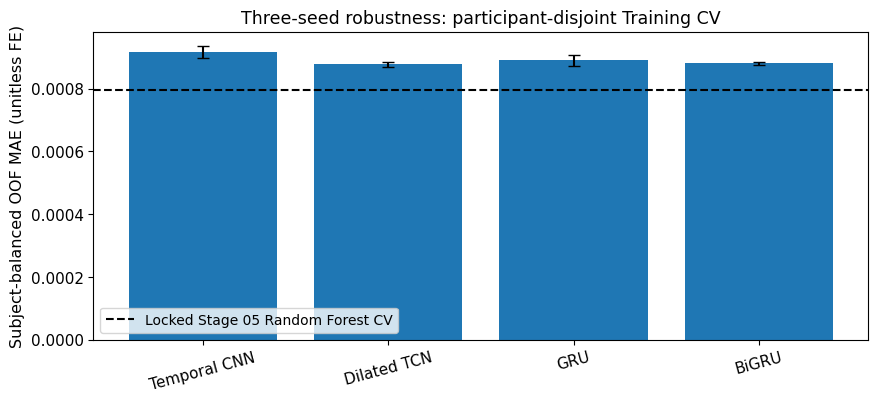

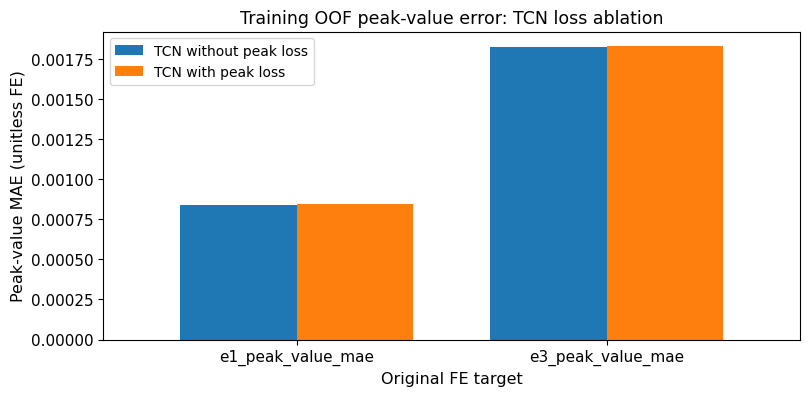

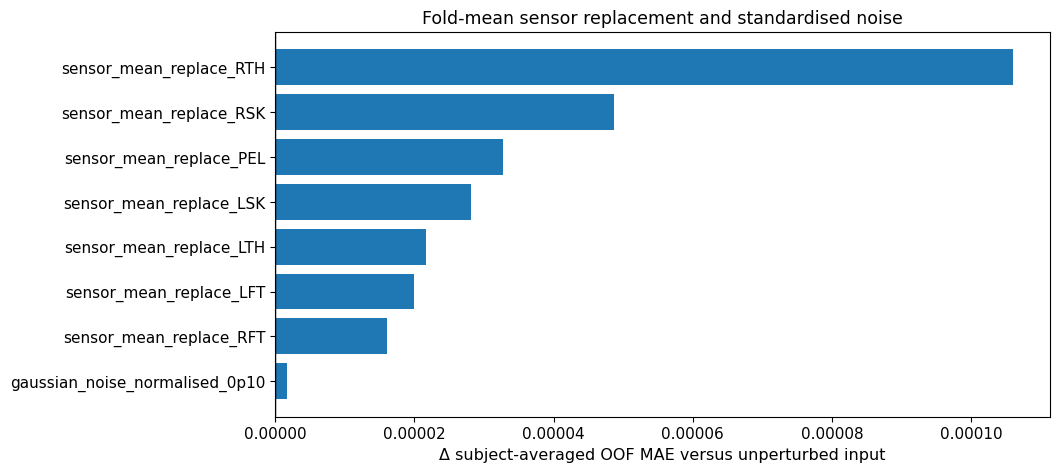

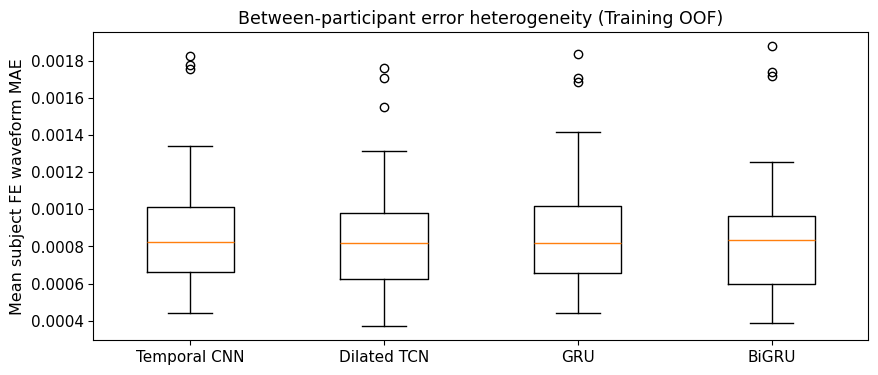

In [10]:
# ======================== 09. Research Result Figures ========================
# ------------------ 1. Three-Seed OOF Comparison ----------------------------
base = summary.loc[summary["config"].isin(ARCHITECTURES)]
base = base.set_index("config").reindex(ARCHITECTURES)
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(
    np.arange(len(base)),
    base["mean_oof_subject_mae"].to_numpy(),
    yerr=base["sd_across_seeds"].to_numpy(),
    capsize=4,
)
ax.axhline(
    prior_rf_cv_mae, linestyle="--", color="black",
    label="Locked Stage 05 Random Forest CV",
)
ax.set_xticks(np.arange(len(base)), base.index, rotation=15)
ax.set_ylabel("Subject-balanced OOF MAE (unitless FE)")
ax.set_title("Three-seed robustness: participant-disjoint Training CV")
ax.legend()
save_figure(fig, output_dir / "07_oof_robustness_comparison.png")
plt.show()

# ------------------ 2. Matched Peak Magnitude Ablation ----------------------
peak_view = ablation.loc[
    ablation["metric"].isin(["e1_peak_value_mae", "e3_peak_value_mae"])
].groupby("metric", as_index=True)[
    ["no_peak_weight_0", "peak_weight_0p25"]
].mean().rename(columns={
    "no_peak_weight_0": "TCN without peak loss",
    "peak_weight_0p25": "TCN with peak loss",
})
fig, ax = plt.subplots(figsize=(9, 4))
peak_view.plot.bar(ax=ax, width=0.75)
ax.set_title("Training OOF peak-value error: TCN loss ablation")
ax.set_xlabel("Original FE target")
ax.set_ylabel("Peak-value MAE (unitless FE)")
ax.tick_params(axis="x", rotation=0)
save_figure(fig, output_dir / "07_peak_loss_ablation.png")
plt.show()

# ----------------- 3. Source Sensor and Noise Perturbations -----------------
sens_plot = sensitivity_summary.sort_values("delta_mae", ascending=True)
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(sens_plot["condition"], sens_plot["delta_mae"])
ax.axvline(0.0, color="black", linewidth=1)
ax.set_xlabel("Δ subject-averaged OOF MAE versus unperturbed input")
ax.set_title("Fold-mean sensor replacement and standardised noise")
save_figure(fig, output_dir / "07_sensor_noise_sensitivity.png")
plt.show()

# ----------------- 4. Participant Heterogeneity by Model -------------------
subject_fig = subject_metrics.loc[
    subject_metrics["config"].isin(ARCHITECTURES)
].groupby(["config", "subject_id"])["mae"].mean().reset_index()
positions = range(len(ARCHITECTURES))
fig, ax = plt.subplots(figsize=(10, 4))
values = [
    subject_fig.loc[subject_fig["config"].eq(name), "mae"].to_numpy()
    for name in ARCHITECTURES
]
ax.boxplot(values, tick_labels=ARCHITECTURES, showfliers=True)
ax.set_ylabel("Mean subject FE waveform MAE")
ax.set_title("Between-participant error heterogeneity (Training OOF)")
save_figure(fig, output_dir / "07_subject_error_heterogeneity.png")
plt.show()


**10. Execution Quality Gate, Source Provenance and Export**

The PASSED gate is emitted only after all 75 jobs, three seeds, five folds, held-out participant identities, sensitivity conditions, curves, and required files are verified. Previous quality gates and model files are not altered; trained networks and large arrays stay in the ignored local cache.


In [11]:
# ===================== 10. Stage 07 Scientific Quality Gate ==================
expected07 = [
    "07_frozen_training_fold_registry.csv",
    "07_job_manifest.csv",
    "07_training_loss_history.csv",
    "07_training_oof_fold_metrics.csv",
    "07_training_oof_subject_metrics.csv",
    "07_training_oof_subject_activity_metrics.csv",
    "07_training_seed_scores.csv",
    "07_training_model_stability_summary.csv",
    "07_peak_loss_ablation.csv",
    "07_paired_subject_bootstrap.csv",
    "07_sensor_noise_sensitivity.csv",
    "07_training_candidate_decision.csv",
    "07_oof_robustness_comparison.png",
    "07_peak_loss_ablation.png",
    "07_sensor_noise_sensitivity.png",
    "07_subject_error_heterogeneity.png",
    "07_robustness_protocol_and_quality_gate.json",
]
assert len(jobs) == len(CONFIGS) * len(SEEDS) * len(FOLDS) == 75
assert jobs[["config", "seed", "fold"]].drop_duplicates().shape[0] == 75
assert jobs["experiment_fingerprint"].nunique() == 75
assert len(history) == 75 * 35
assert len(fold_metric) == 75 * 2
assert seed_metrics.groupby("config")["seed"].nunique().eq(3).all()
assert len(subject_metrics) == 5 * 3 * 29 * 2
assert len(sensitivity) == 8 * 29 * 2
assert summary["mean_oof_subject_mae"].ge(0).all()
assert np.isfinite(summary["mean_oof_subject_mae"]).all()
assert not training_participants & validation_participants
assert not training_participants & reserved_participants
assert not validation_participants & reserved_participants
assert candidate_stage08 == str(primary_options.iloc[0]["candidate"])
assert all((output_dir / name).is_file()
           for name in expected07 if not name.endswith(".json"))
assert gate04["stage04_quality_gate"] == "PASSED"
assert gate05["quality_gate"] == gate06["quality_gate"] == "PASSED"

protocol = {
    "stage": "07",
    "quality_gate": "PASSED",
    "research_status": "complete_training_only",
    "source_article": ARTICLE_ID, "source_version": ARTICLE_VERSION,
    "source_archive_sha256": gate04["original_sha256"],
    "canonical_pair_sha256": source_digest,
    "fixed_upstream_and_code_fingerprints": protocol_inputs,
    "training_subjects": 29, "training_trials": 1354,
    "validation_subjects_reserved_from_new_analysis": 4,
    "validation_trials_reserved_from_new_analysis": 192,
    "test_subjects_reserved": 4, "test_trials_reserved": 183,
    "fit_uses_validation": False, "fit_uses_test": False,
    "score_uses_validation": False, "score_uses_test": False,
    "prior_validation_already_explored_in_stages_05_06": True,
    "model_architectures": list(ARCHITECTURES),
    "controlled_ablation_config": NO_PEAK,
    "model_configs": list(CONFIGS),
    "seeds": list(SEEDS), "folds": list(FOLDS),
    "total_completed_jobs": 75,
    "fixed_epochs": EPOCHS, "batch_size": BATCH_SIZE,
    "peak_weight": PEAK_WEIGHT, "learning_rate": LEARNING_RATE,
    "ablation_peak_weight": 0.0,
    "original_imu_contract": [101, 42],
    "original_fe_contract": [11, 2],
    "original_fe_units": "unitless",
    "native_fe_indices_without_interpolation": True,
    "fold_normalisation_fit_only": True,
    "locked_classical_comparator": {
        "model": "Random Forest",
        "training_cv_mae": prior_rf_cv_mae,
        "stage": "05",
    },
    "predeclared_primary_metric": "mean of 3 seed-specific participant-balanced Training OOF waveform MAEs",
    "ablation_is_not_primary_model_candidate": True,
    "provisional_final_candidate_from_training_only": candidate_stage08,
    "paired_cluster_bootstrap_draws": 2000,
    "sensitivity": {
        "configuration": "Dilated TCN",
        "seed": SEEDS[0],
        "perturbations": 8,
        "sensor_replacement": "fold-Training-mean",
        "noise_normalised_sd": 0.10,
        "causal_sensor_importance_claimed": False,
    },
    "run_device": DEVICE, "torch_version": torch.__version__,
    "numpy_version": np.__version__, "pandas_version": pd.__version__,
    "model_weights_committed": False,
    "external_or_clinical_validation": False,
}
gate_path = output_dir / "07_robustness_protocol_and_quality_gate.json"
gate_path.write_text(json.dumps(protocol, indent=2) + "\n",
                     encoding="utf-8")
assert all((output_dir / name).is_file() for name in expected07)
print("STAGE 07 | MULTI-SEED ROBUSTNESS QUALITY GATE: PASSED")
print("Completed Training-only jobs:", len(jobs))
print("Stage 07 evidence files:", len(expected07))
print("Provisional Training-only candidate:", candidate_stage08)
print("Test participants scored: 0")
download_outputs_from_colab(
    folder="biomechanical_load_estimation/output", stage="07",
)


STAGE 07 | MULTI-SEED ROBUSTNESS QUALITY GATE: PASSED
Completed Training-only jobs: 75
Stage 07 evidence files: 17
Provisional Training-only candidate: Random Forest (Stage 05 locked)
Test participants scored: 0
------------------------------------------------------------------------
Notebook stage: 07
Files packaged: 17
  + 07_frozen_training_fold_registry.csv
  + 07_job_manifest.csv
  + 07_oof_robustness_comparison.png
  + 07_paired_subject_bootstrap.csv
  + 07_peak_loss_ablation.csv
  + 07_peak_loss_ablation.png
  + 07_robustness_protocol_and_quality_gate.json
  + 07_sensor_noise_sensitivity.csv
  + 07_sensor_noise_sensitivity.png
  + 07_subject_error_heterogeneity.png
  + 07_training_candidate_decision.csv
  + 07_training_loss_history.csv
  + 07_training_model_stability_summary.csv
  + 07_training_oof_fold_metrics.csv
  + 07_training_oof_subject_activity_metrics.csv
  + 07_training_oof_subject_metrics.csv
  + 07_training_seed_scores.csv
Download ZIP from Colab Contents: /content/bi

**11. Scientific Interpretation, Decision Boundary and Stage 08 Preparation**

After genuine execution, interpret the **mean and between-seed variation** of Training out-of-fold subject-balanced waveform error for four architecture families, keeping physical FE peak errors separate from average pointwise prediction. The GRU and BiGRU must be discussed with their actual parameter counts and training stability, not assumed to have matched capacities.

For the controlled Dilated TCN peak-loss experiment, distinguish changes in waveform, peak magnitude and native-grid peak location. A smaller training loss does not automatically imply improved error on unseen participants; the participant-disjoint Out-of-Fold results are the relevant evidence. Likewise, fold-mean sensor replacement and fixed noise perturbation quantify **model sensitivity under specified artificial inputs**, not biomechanical causality or a recommendation to remove real sensors.

Any participant-cluster bootstrap interval here is an **exploratory** interval calculated across the 29 Training participants, with model seeds averaged within participant. It cannot demonstrate independent-cohort generalisation; model and architecture selection are still development processes.

The predeclared primary candidate rule compares the three-seed mean Training OOF error for Temporal CNN, Dilated TCN, GRU and BiGRU against the locked Stage 05 Random Forest Training score. The no-peak ablation is a diagnostic and **cannot enter the primary model-selection pool**. The user must explicitly approve the final protocol before any Test evaluation.

**Stage 08 — Frozen Final Evaluation and Research Synthesis:** Freeze the chosen model, weights/loss, training recipe, random seeds, evaluation metrics, participant handling and one-time Test procedure. Only then, with specific approval, may the four reserved Test participants be evaluated. The final cross-stage research report and readable GitHub presentation will subsequently be produced in the project README and supporting documentation rather than an unnecessary additional notebook.

**Execution state:** No Stage 07 metrics or results should be written into this interpretation until the full 75-job experiment actually runs and its quality gate passes.
